In [1]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
# make font size serif
plt.rcParams['font.family'] = 'serif'
# make all font size 14
plt.rcParams['font.size'] = 14


import numpy as np
import pandas as pd
import glob
from PIL import Image
import io
from scipy.spatial import ConvexHull
from scipy import ndimage

# go to above directory
import os
os.chdir('..')

581


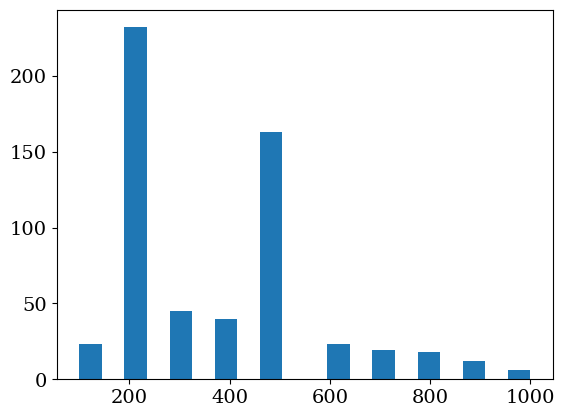

In [2]:
# boxes where constellations are found
constellation_slices_filenames = glob.glob('web-images/*.png')
print(len(constellation_slices_filenames))
length_of_boxes = np.asarray([float(f.split('_')[-1].strip('.png')) for f in constellation_slices_filenames])
plt.hist(length_of_boxes, bins=20);

In [3]:
# getting images from firebase
import firebase_admin
from firebase_admin import credentials, storage, firestore

# Download a service account key from Firebase console:
# Project Settings → Service accounts → Generate new private key
cred = credentials.Certificate('stats/firebase-key.json')
firebase_admin.initialize_app(cred, {
    'storageBucket': 'galactic-constellations.firebasestorage.app'
})

db = firestore.client()
bucket = storage.bucket()

# List all submitted images
blobs = list(bucket.list_blobs(prefix='generated-constellations/'))
print(f'{len(blobs)} images')

96 images


In [4]:
c_size = []
box_size = []
MIN_COMPONENT = 50  # pixels
for blob in bucket.list_blobs(prefix='generated-constellations/'):
    if not blob.name.endswith('.png'):
        continue
    try:
        data = blob.download_as_bytes()
        img = np.array(Image.open(io.BytesIO(data)).convert('RGB'))
    except:
        continue
    
    # HSV conversion
    imgf = img.astype(float) / 255.0
    r, g, b = imgf[:,:,0], imgf[:,:,1], imgf[:,:,2]
    maxc = np.maximum(r, np.maximum(g, b))
    minc = np.minimum(r, np.minimum(g, b))
    v = maxc
    s = np.where(maxc > 0, (maxc - minc) / maxc, 0)
    diff = maxc - minc
    h = np.zeros_like(v)
    mr = (maxc == r) & (diff > 0)
    mg = (maxc == g) & (diff > 0)
    mb = (maxc == b) & (diff > 0)
    h[mr] = ((g[mr] - b[mr]) / diff[mr]) % 6
    h[mg] = ((b[mg] - r[mg]) / diff[mg]) + 2
    h[mb] = ((r[mb] - g[mb]) / diff[mb]) + 4
    h = h / 6.0

    # Teal mask
    teal = (h > 0.4) & (h < 0.55) & (s > 0.3) & (v > 0.3)

    # Keep only large connected components
    labeled, n = ndimage.label(teal)
    sizes = ndimage.sum(teal, labeled, range(1, n + 1))
    big = [i + 1 for i, sz in enumerate(sizes) if sz >= MIN_COMPONENT]
    clean = np.isin(labeled, big)

    if clean.sum() < 3:
        continue

    points = np.argwhere(clean)
    
    hull = ConvexHull(points)
    hull_pts = points[hull.vertices]
    
    # Max distance between any two hull vertices
    from scipy.spatial.distance import pdist
    max_dist_px = pdist(hull_pts).max()
    
    # As fraction of image diagonal
    side_length = img.shape[0]
    max_dist_frac = max_dist_px / side_length
    
    name = blob.name.split('/')[-1]
    image_size = float(name.split('size_')[-1].split('_')[0])
    c_size.append(image_size*max_dist_frac)
    box_size.append(np.sqrt(2)*image_size)
    #print(name, max_dist_frac.round(2), image_size)

C:\Users\cmlam\AppData\Local\Temp\ipykernel_17644\3833356453.py:19: RuntimeWarning: invalid value encountered in divide
  s = np.where(maxc > 0, (maxc - minc) / maxc, 0)


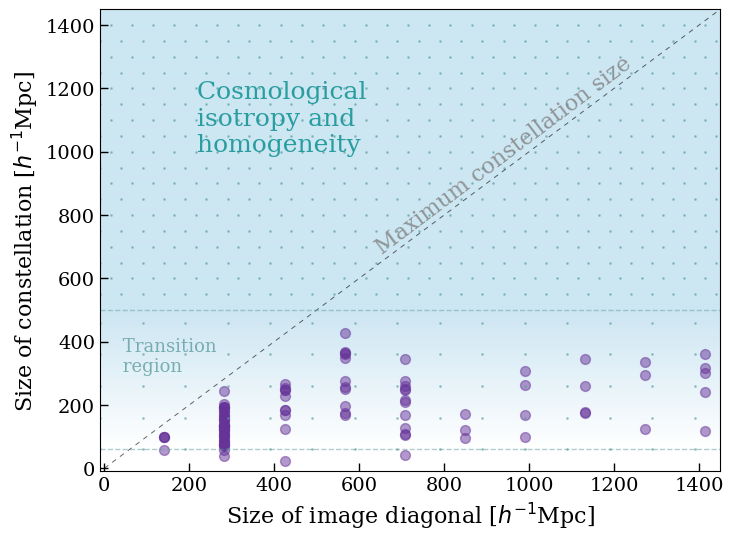

In [6]:
fig = plt.figure(figsize=(8,6))

plt.scatter(box_size, c_size, s=50, alpha=.5, color='rebeccapurple');
plt.xlabel(r'Size of image diagonal [$h^{-1}$Mpc]', fontsize=16);
plt.ylabel(r'Size of constellation [$h^{-1}$Mpc]', fontsize=16);
# draw y=x line
x = np.linspace(0, 1500, 100)
plt.plot(x, x, 'k--', linewidth=.7, alpha=.6, dashes=(5, 5));
plt.xlim(-10, 1450)
plt.ylim(-10, 1450)
# add text over line
plt.text(630, 680, 'Maximum constellation size', rotation=37, fontsize=16, color='gray', alpha=0.8);
# put ticks inside plot
plt.tick_params(direction='in', length=6, width=1, colors='black', grid_color='gray', grid_alpha=0.5);

# shade the background color with a gradient from white to light blue in the y direction
grad_color = (.85, .95, .98)
grad_color = (.8, .9, .95)

gradient_start = 60 # starting y value of gradient
gradient_end = 500 # ending y value of gradient
gradient = np.linspace(1, 0, 256).reshape(-1, 1)
cmap = LinearSegmentedColormap.from_list('gradient', ['white', grad_color])
plt.imshow(gradient, extent=[-10, 1450, gradient_start, gradient_end], aspect='auto', cmap=cmap, alpha=1);
# make background above y= gradient_end solid
plt.fill_between(x-10, gradient_end, 1450, color=grad_color, alpha=1);
# add blue text in shaded region
plt.text(200, 1000, ' Cosmological \n isotropy and \n homogeneity', fontsize=18, color='darkcyan', alpha=.8);
# add faint grid of dots above y = gradient_end
for y in range(gradient_end+50, 1450, 50):
    add = 0
    if y % 100 == 0:
        add = 25
    plt.scatter(np.arange(-10, 1450, 50)+add, [y]*len(np.arange(-10, 1450, 50)), s=1, color='cadetblue', alpha=0.5);
    
    
for y in range(gradient_start, gradient_end, 100):
    add = 0
    if y % 200 == 0:
        add = 50
    plt.scatter(np.arange(-10, 1450, 100)+add, [y]*len(np.arange(-10, 1450, 100)), s=1, color='cadetblue', alpha=0.5);
    
    
# for each image size, find the mean and standard error of constellation sizes, and plot as error bars
box_size_unique = np.unique(box_size)
c_size_mean = []
c_size_sem = []
for bs in box_size_unique:
    c_size_bs = [c for c, b in zip(c_size, box_size) if b == bs]
    c_size_mean.append(np.mean(c_size_bs))
    c_size_sem.append(np.std(c_size_bs) / np.sqrt(len(c_size_bs)))
av_color = 'black'
#plt.errorbar(box_size_unique, c_size_mean, yerr=c_size_sem, fmt='o', color=av_color, ecolor=av_color, elinewidth=2, capsize=4, label='Mean constellation size');
    
# add hotizontal lines at gradient start and end
plt.axhline(gradient_start, color='cadetblue', alpha=0.5, linestyle='--', linewidth=1);
plt.axhline(gradient_end, color='cadetblue', alpha=0.5, linestyle='--', linewidth=1);
# add vetical text that says "transition to isotropy" between the gradient start and end lines
plt.text(30, 305, ' Transition\n region', rotation=0, fontsize=13, color='cadetblue', alpha=0.8);
# save
plt.savefig('stats/constellation_size_vs_box_size.png', dpi=500, bbox_inches='tight');

426.4178780045886 1414.213562373095


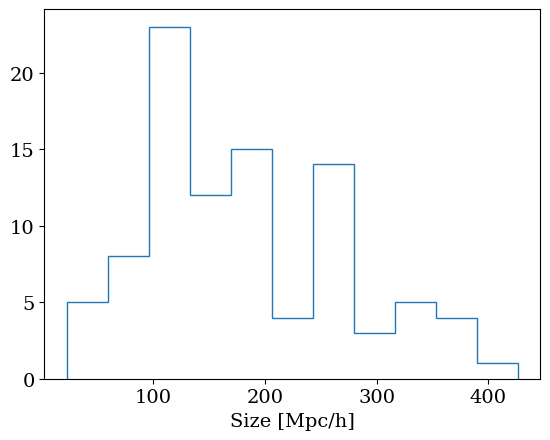

In [11]:
plt.hist(c_size, bins=11, histtype='step', label='Constellation Size');
plt.xlabel('Size [Mpc/h]');
print(np.max(c_size), np.max(box_size))

In [5]:
# add manually found ones: fish, W, woman
c_size.extend([300, 100, 100])
box_size.extend([s*np.sqrt(2) for s in [1000, 700, 200]])